## Motivação  

Até aqui, o curso fez perguntas de inferência. Esta aula abre o bloco de aprendizado de máquina, e a pergunta muda de natureza. Queremos usar essa relação para prever, e um modelo de previsão se julga pelo erro que comete em dados novos, não nos dados com que aprendeu.

## Objetivos  

Calcular e interpretar o intercepto e a inclinação de uma regressão linear simples.
Medir o erro de um modelo com MAE, RMSE e 
 e compará-lo com um modelo de referência.
Explicar por que o erro de treino é otimista e aplicar o protocolo de teste cego com validação cruzada de 5 dobras.
Ajustar e comparar uma regressão linear múltipla nas mesmas dobras, interpretando seus coeficientes.
Diagnosticar um modelo pelos gráficos de resíduos.
Explicar o funcionamento da regularização (Ridge, Lasso e ElasticNet) e reconhecer a mesma ideia em outros modelos de IA.

## Preparando os dados

In [18]:
# Importa as bibliotecas e define o tema dos gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from scipy import stats
from scipy.interpolate import CubicSpline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import (
    KFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", palette="colorblind")

In [19]:
# Baixa a base pelo scikit-learn e salva a cópia local - Executar apenas na primeira vez
'''
from sklearn.datasets import fetch_california_housing

(
    fetch_california_housing(as_frame=True)
    .frame
    .to_csv("../../data/california_housing.csv", index=False)
)
'''

'\nfrom sklearn.datasets import fetch_california_housing\n\n(\n    fetch_california_housing(as_frame=True)\n    .frame\n    .to_csv("../../data/california_housing.csv", index=False)\n)\n'


Na primeira execução, fetch_california_housing baixa os dados da internet e guarda uma cópia em ~/scikit_learn_data. as_frame=True devolve os dados como tabela do pandas, e .frame reúne os atributos e a resposta MedHouseVal

In [20]:
nomes_colunas = {
    "MedInc" : "RendaMediana",
    "HouseAge" : "IdadeImovel",
    "AveRooms" : "Comodos",
    "AveBedrms" : "Quartos",
    "Population" : "Populacao",
    "AveOccup" : "Moradores",
    "MedHouseVal" : "ValorImovel",
}

In [21]:
# Carrega a base de grupos de quarteirões da Califórnia

quarteiroes = ( pd.read_csv("../../data/california_housing.csv")
    .rename(columns = nomes_colunas)
)

quarteiroes.head()

,RendaMediana,IdadeImovel,Comodos,Quartos,Populacao,Moradores,Latitude,Longitude,ValorImovel
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Coluna	Unidade  
Renda mediana das famílias do grupo	Dezenas de milhares de dólares (US$ 10 mil)  
Idade mediana das casas	Anos  
Número médio de cômodos por domicílio	Cômodos  
Número médio de quartos por domicílio	Quartos  
População do grupo	Pessoas  
Número médio de moradores por domicílio	Pessoas  
Latitude, Longitude	Posição geográfica do grupo	Graus  
Valor mediano das casas, a variável que queremos prever	Centenas de milhares de dólares (US$ 100 mil)  

## Roteiro:

1. Inspeção estrutural da base;
2. Separação do teste cego;
3. Exploração do conjunto de treino;
4. Criação do baseline;
5. Configuração da validação cruzada;
6. Treinamentos dos modelos;
7. Avaliar modelos por validação cruzada;
8. Ajustar modelo vencedor;

### 1. Inspeção estrutural da base

In [22]:
quarteiroes.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   RendaMediana  20640 non-null  float64
 1   IdadeImovel   20640 non-null  float64
 2   Comodos       20640 non-null  float64
 3   Quartos       20640 non-null  float64
 4   Populacao     20640 non-null  float64
 5   Moradores     20640 non-null  float64
 6   Latitude      20640 non-null  float64
 7   Longitude     20640 non-null  float64
 8   ValorImovel   20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [23]:
quarteiroes.duplicated().sum()

np.int64(0)

In [24]:
quarteiroes.head()


# Resumo das nove colunas

resumo_estatistico = (
    quarteiroes
    .describe()
    .T
    .round(2)
)

resumo_estatistico

,count,mean,std,min,25%,50%,75%,max
RendaMediana,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
IdadeImovel,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
Comodos,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
Quartos,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Populacao,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
Moradores,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
ValorImovel,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


### 2. Separação do teste cego;

In [28]:
# Separa 20% das linhas como teste cego, antes de qualquer análise

X = quarteiroes.drop(columns="ValorImovel")
y = quarteiroes["ValorImovel"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

train = X_train.assign(ValorImovel=y_train)

print(f"Treino: {len(X_train)} linhas · Teste cego: {len(X_test)} linhas")


Treino: 16512 linhas · Teste cego: 4128 linhas


### 3. Exploração do conjunto de treino;

Gráfico de Apoio: bairros de renda mais alta têm casas mais caras? Antes do modelo, olhamos para a resposta e para a relação dela com a renda.

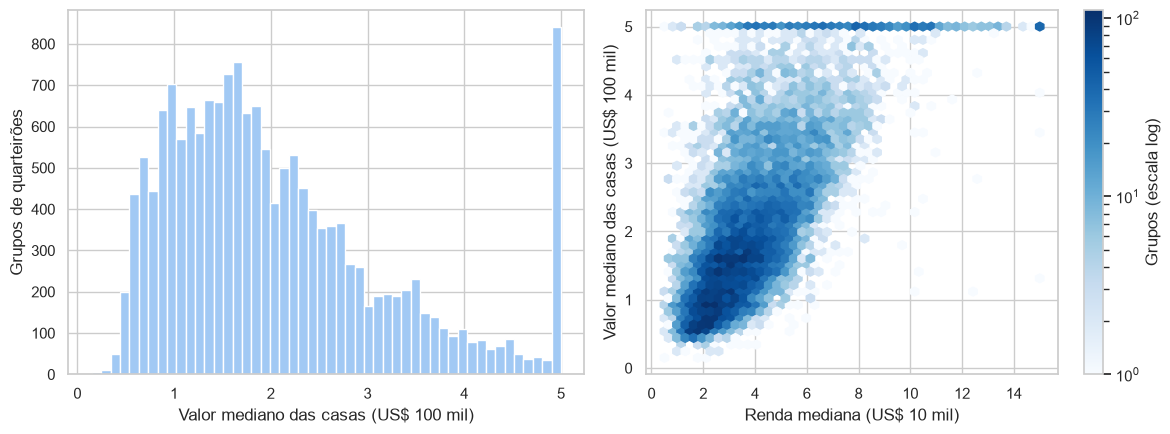

In [29]:
# Distribuição do valor das casas e relação com a renda
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(train["ValorImovel"], bins=50, color="#A1C9F4", edgecolor="white")
axes[0].set(xlabel="Valor mediano das casas (US$ 100 mil)",
            ylabel="Grupos de quarteirões")

hexes = axes[1].hexbin(train["RendaMediana"], train["ValorImovel"], gridsize=45,
                       cmap="Blues", mincnt=1, bins="log")
fig.colorbar(hexes, ax=axes[1], label="Grupos (escala log)")
axes[1].set(xlabel="Renda mediana (US$ 10 mil)",
            ylabel="Valor mediano das casas (US$ 100 mil)")

plt.tight_layout()
plt.show()

In [31]:
# Proporção de grupos no teto de 5,0
teto = (train["ValorImovel"] >= 5).mean()

print(f"Grupos no teto de U$$ 500 mil: {teto:.1%}")

Grupos no teto de U$$ 500 mil: 4.9%


### Dempstração didática de Ajustando a reta 

In [32]:
# Reta de mínimos quadrados ajustada com o scikit-learn

m1 = LinearRegression()
m1.fit(X_train[["RendaMediana"]], y_train)

print(f"β0 = {m1.intercept_:.4f} · β1 = {m1.coef_[0]:.4f}")

new_incomes = pd.DataFrame({"RendaMediana": [2, 4, 8]})
m1.predict(new_incomes)

β0 = 0.4446 · β1 = 0.4193


array([1.28327428, 2.12195127, 3.79930524])

Interpretação $\beta_1$: Cada aumento de 1 unidade na renda mediana (US$ 10 mil/ano) está associado a um aumento médio de 0,419 unidade no valor mediano das casas (US$ 41,9 mil).  
Interpretação $\beta_0$:  Represente 0,445, ou US$ 44,5 mil para renda zero. Não tem interpretação prática, pois não existem bairros com renda zero na base. (é apenas uma âncora geométrica - indica associação, não causalidade, e só vale dentro da faixa de renda observada no treino).   

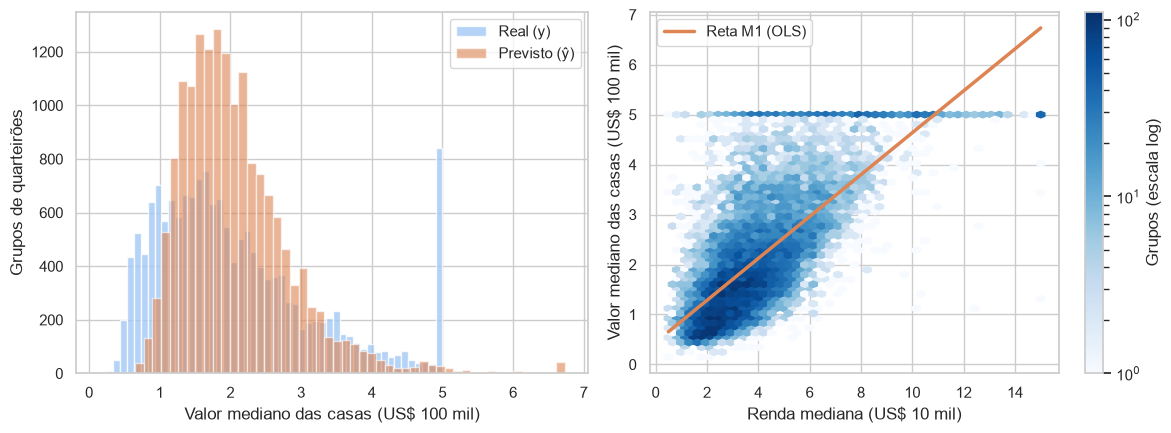

In [ ]:
# Previsões do m1 no conjunto de treino e grade para desenhar a reta (Grafico gerado por IA)

y_pred_m1 = m1.predict(X_train[["RendaMediana"]])
income_grid = pd.DataFrame({"RendaMediana": np.linspace(train["RendaMediana"].min(), train["RendaMediana"].max(), 100)})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Painel 1: Histograma comparando valores reais vs. previstos pelo m1
axes[0].hist(train["ValorImovel"], bins=50, color="#A1C9F4", edgecolor="white", alpha=0.8, label="Real (y)")
axes[0].hist(y_pred_m1, bins=50, color="#DD8452", edgecolor="white", alpha=0.6, label="Previsto (ŷ)")
axes[0].set(xlabel="Valor mediano das casas (US$ 100 mil)", ylabel="Grupos de quarteirões")
axes[0].legend()

# Painel 2: Hexbin com a reta de mínimos quadrados (m1) sobreposta
hexes = axes[1].hexbin(train["RendaMediana"], train["ValorImovel"], gridsize=45,
                       cmap="Blues", mincnt=1, bins="log")
axes[1].plot(income_grid["RendaMediana"], m1.predict(income_grid), color="#DD8452",
             linewidth=2.5, label="Reta M1 (OLS)")
fig.colorbar(hexes, ax=axes[1], label="Grupos (escala log)")
axes[1].set(xlabel="Renda mediana (US$ 10 mil)", ylabel="Valor mediano das casas (US$ 100 mil)")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()



### 4. Criação do baseline;

In [ ]:
baseline = DummyRegressor(strategy="mean").fit(X_train[["RendaMediana"]], y_train)


### Demostração didática:  
- Previsões do modelo de referência e do M1 nos próprios dados de ajuste

In [36]:
predictions = {
    "Referência (média)": baseline.predict(X_train[["RendaMediana"]]),
    "M1 (renda)": m1.predict(X_train[["RendaMediana"]]),
}

In [37]:
# MAE, RMSE e R² de cada modelo
fit_metrics = (
    pd.DataFrame(
        {
            name: {
                "MAE": mean_absolute_error(y_train, pred),
                "RMSE": root_mean_squared_error(y_train, pred),
                "R²": r2_score(y_train, pred),
            }
            for name, pred in predictions.items()
        }
    )
    .T
    .round(4)
)

fit_metrics

,MAE,RMSE,R²
Referência (média),0.9139,1.1562,0.000
M1 (renda),0.6250,0.8361,0.477


O modelo simples (M1) supera o palpite ingênuo da média (referência).  
MAE menor no M1 (erra o valor mediano de um bairro em cerca de US$ 62 mil, para mais ou para menos, já referencia erra mais);  
RMSE menor no M1 (Diante do RMSE de 1,16 da referência, a renda reduz o erro típico de US$ 116 mil para US$ 84 mil);  
R2: 0,48 indica que a renda explica cerca de 48% da variação do valor entre bairros. Os outros 52% ficam nos resíduos. A referência tem r2 = 0 por definição.

Porem esses números ainda não servem para escolher o melhor modelo, pois foram medidos nos dados que o modelo já conhecia.

### 5. Validação cruzada

In [38]:
# Validação cruzada com 5 dobras para o M1

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"rmse": "neg_root_mean_squared_error", "r2": "r2"}

cv_m1 = cross_validate(LinearRegression(), X_train[["RendaMediana"]], y_train, cv=kfold,
                       scoring=scoring, return_train_score=True)

folds_m1 = pd.DataFrame(
    {
        "r2_treino": cv_m1["train_r2"],
        "r2_validacao": cv_m1["test_r2"],
        "rmse_validacao": -cv_m1["test_rmse"],
    },
    index=pd.RangeIndex(1, 6, name="dobra"),
)

folds_m1.round(4)

,r2_treino,r2_validacao,rmse_validacao
dobra,,,
1,0.4779,0.4733,0.8525
2,0.4782,0.4723,0.8372
3,0.4714,0.4995,0.8170
4,0.4797,0.4659,0.8482
5,0.4778,0.4734,0.8255


In [39]:
# Média e desvio-padrão das métricas nas cinco dobras
summary_m1 = (
    folds_m1
    .agg(["mean", "std"])
    .round(4)
)

summary_m1

,r2_treino,r2_validacao,rmse_validacao
mean,0.4770,0.4769,0.8361
std,0.0032,0.0130,0.0150


O r2 médio de validação fica em torno de 0,48, e o RMSE, em 0,84, praticamente os valores obtidos nos dados de ajuste.  

As médias do r2 de treino e de validação coincidem em 0,477. O desvio padrão é baixo, porem a renda sozinha explica menos da metade da variação dos preços (~48%), deixando espaço para melhorar o modelo com mais atributos. 

### 6. Treinamento do modelo com Regressão linear múltipla

O M1 mostra uma associação de 48% entre renda e valor, mas ignora as demais características das casas. Incluir esses atributos reduz o erro em dados novos? E o ganho visto na validação cruzada se mantém no teste cego?  

M1 (simples): RendaMediana.  
M2 (múltiplo): RendaMediana, IdadeImovel, Comodos, Quartos, Populacao, Moradores.

In [40]:
# M2: seis atributos, avaliados nas mesmas cinco dobras do M1

features_m2 = ["RendaMediana", "IdadeImovel", "Comodos", "Quartos", "Populacao", "Moradores"]

cv_m2 = cross_validate(LinearRegression(), X_train[features_m2], y_train, cv=kfold,
                       scoring=scoring, return_train_score=True)

comparison = pd.DataFrame(
    {
        "M1_r2": cv_m1["test_r2"],
        "M2_r2": cv_m2["test_r2"],
        "M1_rmse": -cv_m1["test_rmse"],
        "M2_rmse": -cv_m2["test_rmse"],
    },
    index=pd.RangeIndex(1, 6, name="dobra"),
)

In [41]:
# Média e desvio-padrão de M1 e M2 nas cinco dobras

comparison_summary = (
    comparison
    .agg(["mean", "std"])
    .round(4)
)

comparison_summary

,M1_r2,M2_r2,M1_rmse,M2_rmse
mean,0.4769,0.5439,0.8361,0.7807
std,0.0130,0.0187,0.0150,0.0208


A adição de atibutos melhora o desenpenho preditivo do modelo que passa conseguir explicar 54% da variação do valor mediano das casas, enquanto o erro típico cai de aproximadamente do RMSE cai de 0.84 para 0.78.

#### Treinamento com unidades padronizadas

Na regressão múltipla, cada coeficiente mede a associação de um atributo com 
 mantidos constantes os demais atributos do modelo. É aí que ela difere da regressão simples.

In [42]:
# Coeficientes do M2 em unidades originais e padronizadas

m2 = LinearRegression().fit(X_train[features_m2], y_train)
m2_scaled = make_pipeline(StandardScaler(), LinearRegression()).fit(
    X_train[features_m2], y_train
)

coefficients = (
    pd.DataFrame(
        {
            "original": m2.coef_,
            "padronizado": m2_scaled[-1].coef_,
            "correlacao_com_y": X_train[features_m2].corrwith(y_train),
        },
        index=features_m2,
    )
    .round(4)
)

coefficients

,original,padronizado,correlacao_com_y
RendaMediana,0.5462,1.0400,0.6906
IdadeImovel,0.0168,0.2116,0.1037
Comodos,-0.2239,-0.5346,0.1585
Quartos,1.1155,0.4832,-0.0514
Populacao,0.0000,0.0263,-0.0260
Moradores,-0.0046,-0.0535,-0.0220


#### Análise de coeficiente negativo

In [44]:
# Coeficiente de Comodos em três especificações diferentes
specs = {
    "só Comodos": ["Comodos"],
    "Comodos + RendaMediana": ["Comodos", "RendaMediana"],
    "M2 (seis atributos)": features_m2,
}

for name, cols in specs.items():
    coefs = pd.Series(LinearRegression().fit(X_train[cols], y_train).coef_, index=cols)
    print(f"{name:<20} β(Comodos) = {coefs['Comodos']:+.4f}")

rooms_corr = X_train[["Quartos", "RendaMediana"]].corrwith(X_train["Comodos"])

print(f"\nCorrelação Comodos × Quartos = {rooms_corr['Quartos']:.2f}")
print(f"Correlação Comodos × RendaMediana    = {rooms_corr['RendaMediana']:.2f}")

só Comodos           β(Comodos) = +0.0768
Comodos + RendaMediana β(Comodos) = -0.0402
M2 (seis atributos)  β(Comodos) = -0.2239

Correlação Comodos × Quartos = 0.84
Correlação Comodos × RendaMediana    = 0.34


- Sozinho, Comodos tem coeficiente positivo: bairros com casas maiores valem mais. Parte disso, porém, acontece porque casas maiores ficam em bairros mais ricos.  
- Quando a renda entra no modelo, o coeficiente fica negativo. Entre bairros da mesma renda, ter mais cômodos deixa de estar associado a valores maiores, e parte do efeito aparente dos cômodos se revela efeito da renda. Esse é o viés de variável omitida: quando um atributo relevante fica de fora, os coeficientes dos outros absorvem a sua influência.

- Com quartos, o coeficiente fica ainda mais negativo.  
Cômodos e quartos têm correlação de 0,84, e quando um cresce o outro quase sempre cresce junto. Manter os quartos constantes e aumentar os cômodos é raro nos dados, e o modelo divide o efeito entre os dois de forma instável, com um coeficiente negativo e o outro fortemente positivo. É a multicolinearidade.

### 7. Avaliar o modelo

- #### Out-of-fold, ou “fora da dobra”: a previsão de cada bairro vem de um modelo que não o usou no ajuste.

In [ ]:
# Previsões fora da dobra para todo o conjunto de treino

oof_m2 = cross_val_predict(LinearRegression(), X_train[features_m2], y_train, cv=kfold)
residuals_m2 = y_train - oof_m2

print(f"Previsões negativas: {(oof_m2 < 0).sum()} · "
      f"acima de U$$ 500 mil: {(oof_m2 > 5).sum()} · máxima: {oof_m2.max():.2f}")

Previsões negativas: 7 · acima de U$$ 500 mil: 185 · máxima: 8.01


O modelo gera previsões impossíveis ou fora dos limites registrados pela base quando encontra combinações extremas de atributos.  

- Para 7 bairros, o modelo estimou que o valor mediano das casas seria menor que zero, algo impossível no mercado imobiliário.  

- Para 185 bairros, o modelo previu valores acima de US$ 500 mil (5.0). Embora casas reais possam valer mais que isso, o censo truncou todos os imóveis caros exatamente em 5,0; logo, o modelo está extrapolando além do limite superior que existe nos dados de treino.

- A previsão mais alta gerada pelo modelo chegou a US$ 801 mil (8,01), ultrapassando em mais de US$ 300 mil o teto máximo registrado na base.

- #### Avaliação final no teste cego

In [48]:
# Ajuste final no conjunto de treino inteiro e previsões no teste cego

final_models = {"M1": (["RendaMediana"], cv_m1), "M2": (features_m2, cv_m2)}

test_predictions = {
    name: LinearRegression().fit(X_train[cols], y_train).predict(X_test[cols])
    for name, (cols, _) in final_models.items()
}

In [49]:
# Desempenho na validação cruzada e no teste cego, lado a lado
final_results = (
    pd.DataFrame(
        {
            name: {
                "R² (CV)": cv["test_r2"].mean(),
                "R² (teste)": r2_score(y_test, test_predictions[name]),
                "RMSE (CV)": -cv["test_rmse"].mean(),
                "RMSE (teste)": root_mean_squared_error(y_test, test_predictions[name]),
                "MAE (teste)": mean_absolute_error(y_test, test_predictions[name]),
            }
            for name, (_, cv) in final_models.items()
        }
    )
    .T
    .rename_axis("modelo")
    .round(4)
)

final_results

,R² (CV),R² (teste),RMSE (CV),RMSE (teste),MAE (teste)
modelo,,,,,
M1,0.4769,0.4589,0.8361,0.8421,0.6299
M2,0.5439,0.5099,0.7807,0.8014,0.5792


No teste cego, o ganho do M2 se mantém: r2 de 0,51 (explica cerca de 51% da variação dos preços) contra 0,46, e RMSE de 0,80 contra 0,84.  
Os dois modelos vão um pouco pior no teste do que na validação cruzada, com o r2 caindo entre 1,4 e 1,8 desvio-padrão das dobras.  
A diferença é esperada. O teste é uma única amostra de 4.128 bairros, com a sua própria dose de acaso, e nenhuma estimativa de erro é exata.

O que deixamos de fazer agora pesa tanto quanto o que fizemos. Se o M2 tivesse ido mal no teste, a tentação seria voltar, mudar os atributos e testar de novo. A partir daí, porém, o teste deixaria de ser cego e viraria só mais uma dobra de validação. O número do teste é o resultado a reportar, seja ele bom ou ruim.


### O protocolo inteiro cabe em uma frase: separe o teste antes de olhar os dados, escolha o modelo pela validação cruzada e abra o teste uma única vez, no fim.